# 02 · Exploratory analysis and QC
**Track A**: sample sizes per cell of the 2×2, PCA coloured by group, animal structure. **Environmental panel**: correlations, missingness, seasonality.

In [1]:
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from synera_core.config import find_repo_root, get_settings
warnings.filterwarnings("ignore")
ROOT = find_repo_root()
C = dict(bg="#061424", panel="#0b2037", cyan="#16B5FF", green="#6FD65B", amber="#FFB547", red="#FF4D5E", teal="#19E3B1", text="#EAF2FB", muted="#8FA6BF")
plt.rcParams.update({"figure.facecolor": C["bg"], "axes.facecolor": C["bg"], "axes.edgecolor": C["muted"], "axes.labelcolor": C["text"],
    "text.color": C["text"], "xtick.color": C["muted"], "ytick.color": C["muted"], "grid.color": "#1c3a5c", "axes.grid": True, "grid.linewidth": 0.5,
    "axes.prop_cycle": plt.cycler(color=[C["cyan"], C["green"], C["amber"], C["red"], C["teal"]]), "figure.dpi": 110, "font.size": 9})
SEED = get_settings().seeds.global_seed
RES = ROOT / "artifacts" / "results"

In [2]:
from synera_core.pipeline import track_a as TA
e1, m1 = TA.load_study("OSD-211"); e2, m2 = TA.load_study("OSD-237")
display(pd.DataFrame([TA.cell_counts(m1), TA.cell_counts(m2)], index=["OSD-211 spleen", "OSD-237 skin"]))
print("shared animals:", len(set(m1.animal_id) & set(m2.animal_id)), "of", len(set(m1.animal_id)), "- the two studies are NOT independent")

,control,radiation,unloading,both
OSD-211 spleen,6,6,3,6
OSD-237 skin,6,6,3,6


shared animals: 20 of 21 - the two studies are NOT independent


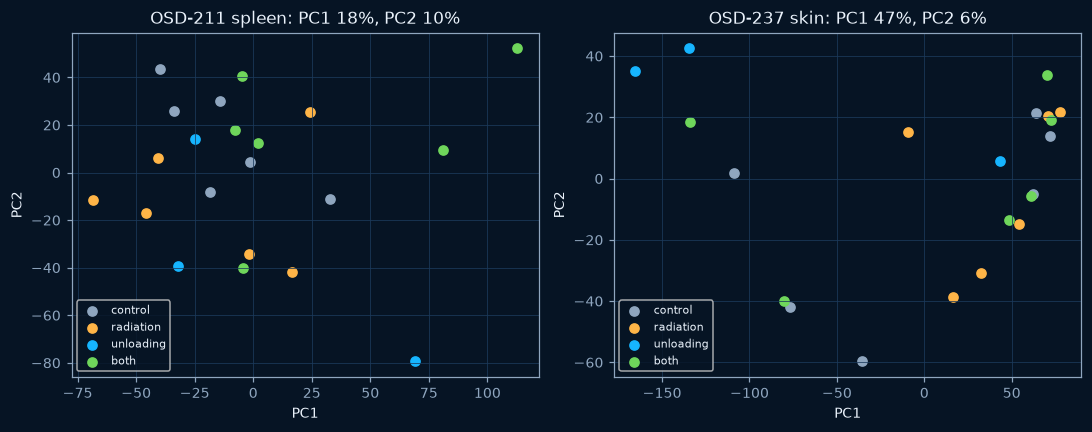

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nm, e, m) in zip(axes, [("OSD-211 spleen", e1, m1), ("OSD-237 skin", e2, m2)]):
    X = e.T.to_numpy(float); X = X - X.mean(0); u, s, _ = np.linalg.svd(X, full_matrices=False); pc = u * s
    grp = m.radiation.astype(str) + m.microgravity.astype(str)
    for g, col, lab in [("00", C["muted"], "control"), ("10", C["amber"], "radiation"), ("01", C["cyan"], "unloading"), ("11", C["green"], "both")]:
        k = (grp == g).to_numpy(); ax.scatter(pc[k, 0], pc[k, 1], c=col, label=lab, s=36)
    ax.set_title(f"{nm}: PC1 {s[0]**2/(s**2).sum():.0%}, PC2 {s[1]**2/(s**2).sum():.0%}"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

Samples do not separate cleanly by group on the leading axes, which is what a weak, noisy interaction signal looks like. The notebook does **not** read anything into the PCs beyond what is tested in `scripts/build_space_biology.py`.

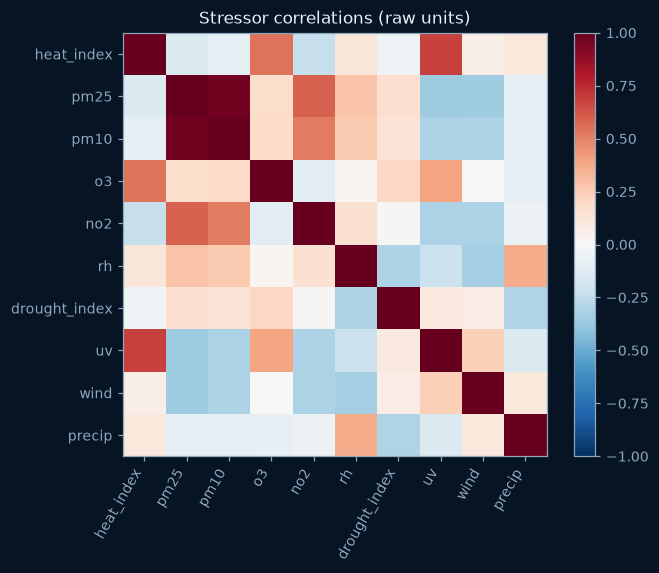

Strongly correlated stressors (|r| >= 0.6) can stand in for each other in an interaction test:
[('heat_index', 'uv', np.float64(0.68)), ('pm25', 'pm10', np.float64(0.97))]


In [4]:
env = pd.read_parquet(ROOT / "data/processed/env_panel.parquet")
cols = ["heat_index","pm25","pm10","o3","no2","rh","drought_index","uv","wind","precip"]
cor = env[cols].corr()
fig, ax = plt.subplots(figsize=(6.4, 5)); im = ax.imshow(cor, cmap="RdBu_r", vmin=-1, vmax=1); ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right"); ax.set_yticks(range(len(cols)), cols)
ax.grid(False); plt.colorbar(im); ax.set_title("Stressor correlations (raw units)"); plt.show()
print("Strongly correlated stressors (|r| >= 0.6) can stand in for each other in an interaction test:")
print([(a, b, round(cor.loc[a, b], 2)) for i, a in enumerate(cols) for b in cols[i+1:] if abs(cor.loc[a, b]) >= 0.6])

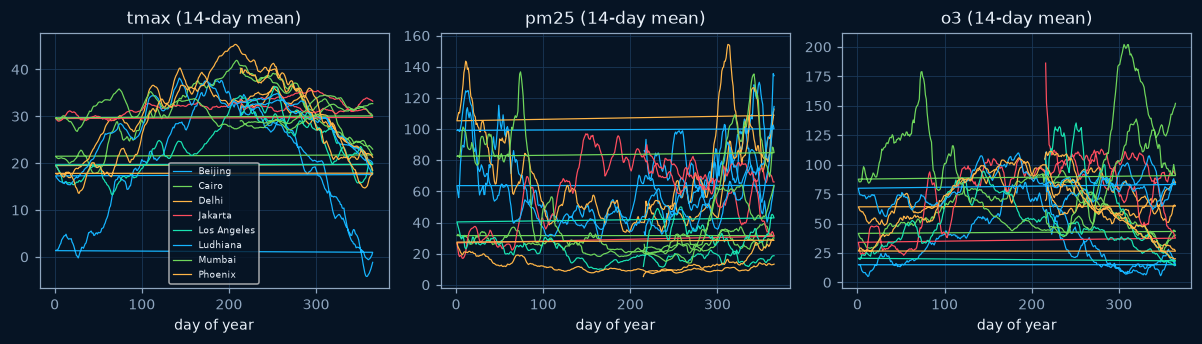

Aug-Dec appear twice (2022 and 2023) and Jan-Jul once: season is partly confounded with year. The engine therefore adjusts for city and seasonality.


In [5]:
env["doy"] = pd.to_datetime(env["date"]).dt.dayofyear
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, v in zip(axes, ["tmax", "pm25", "o3"]):
    for city, g in env.groupby("city"): ax.plot(g["doy"], g[v].rolling(14, min_periods=1).mean(), lw=0.8, label=city)
    ax.set_title(v + " (14-day mean)"); ax.set_xlabel("day of year")
axes[0].legend(fontsize=6); plt.tight_layout(); plt.show()
print("Aug-Dec appear twice (2022 and 2023) and Jan-Jul once: season is partly confounded with year. The engine therefore adjusts for city and seasonality.")